# Pick 10 stocks each industry, from 10 industries. From that 100 stocks, pick 10 with the highest growth in the last month, buy and hold it for the next month. Rebalancing monthly, 10% each stock.


In [23]:
import os
import warnings
import numpy as np
import pandas as pd
from scipy.stats import gmean
import yfinance as yf
import matplotlib.pyplot as plt
import plotly.graph_objects as go
from plotly.subplots import make_subplots
from datetime import datetime, timedelta, date, time
warnings.filterwarnings('ignore')

In [76]:
tickers = ['SPY',"NVDA", "MSFT", "AAPL", "AMZN", "GOOGL", "META", "AVGO", "BRK-B", "TSLA", "JPM",
    "WMT", "LLY", "V", "ORCL", "NFLX", "MA", "XOM", "COST", "PG", "JNJ",
    "HD", "BAC", "ABBV", "PLTR", "KO", "UNH", "PM", "TMUS", "CSCO", "WFC",
    "CRM", "GE", "AMD", "DOW", "NKE", "MCD", "PFE", "TXN", "MRK", "IBM",
    "ADBE", "INTC", "T", "UPS", "AMGN", "QCOM", "VZ", "SO", "BMY", "HON",
    "LIN", "CVX", "CAT", "GS", "NEE", "LOW", "SPGI", "MS", "BLK", "RTX",
    "NOW", "SCHW", "BA", "ISRG", "CI", "MDT", "DE", "ELV", "AXP", "INTU",
    "ADP", "CB", "TJX", "PYPL", "C", "ZTS", "PGR", "DUK", "MMC", "LMT",
    "VRTX", "SYK", "TMO", "BDX", "MO", "ADI", "REGN", "BKNG", "ICE", "ABNB",
    "FDX", "GM", "NSC", "FIS", "HUM", "CL", "GILD", "WM", "EW", "AON",
    "ROST", "DHR", "PNC", "ETN", "ITW", "SHW", "CSX", "MNST", "TRV", "EMR",
    "AEP", "ALL", "GD", "PSX", "HCA", "MCO", "MAR", "APD", "EOG", "LRCX",
    "KLAC", "PCAR", "CDNS", "MCK", "CTAS", "ORLY", "AFL", "STZ", "ANET", "FTNT",
    "KHC", "PAYX", "PH", "MTD", "CTSH", "TGT", "AZO", "IDXX", "TT", "SRE",
    "WELL", "DLR", "F", "CME", "PXD", "ED", "MRNA", "CMI", "NEM", "HSY",
    "WBA", "TEL", "ODFL", "BIIB", "HPQ", "CARR", "AME", "COF", "HES", "D",
    "AIG", "A", "MSI", "EXC", "RSG", "YUM", "HIG", "O", "XEL", "TSCO",
    "CHD", "DFS", "KEYS", "FAST", "EFX", "TDG", "ACN", "BKR", "CEG", "GPN",
    "KMB", "AVB", "VRSK", "FRC", "CDW", "HLT", "CMS", "ROL", "NUE", "ATO",
    "VLO", "ZBH", "QRVO", "IP", "MTB", "FTV", "ULTA", "MLM", "LH", "HOLX",
    "INCY", "WAT", "XYL", "LUV", "PKI", "NVR", "SJM", "PPG", "NDAQ", "DRI",'BTC-USD','GC=F']
# List of companies
df = pd.DataFrame(yf.download(tickers, start='2015-01-01', end='2025-08-01', interval="1d")['Close'])


[*********************100%***********************]  213 of 213 completed
ERROR:yfinance:
4 Failed downloads:
ERROR:yfinance:['DFS', 'PXD', 'PKI']: YFTzMissingError('possibly delisted; no timezone found')
ERROR:yfinance:['FRC']: YFPricesMissingError('possibly delisted; no price data found  (1d 2015-01-01 -> 2025-08-01)')


In [77]:
return_daily = df.pct_change()


In [78]:
return_monthly = (1+return_daily).resample('ME').prod() -1
top_10_columns = pd.DataFrame(return_monthly.apply(lambda x: x.nlargest(20).index.tolist(), axis=1))

# Get the column names for the 10 lowest values in each row
bottom_10_columns = pd.DataFrame(return_monthly.apply(lambda x: x.nsmallest(20).index.tolist(), axis=1))
top_columns = top_10_columns.merge(bottom_10_columns, left_index= True, right_index = True, how = 'outer')
top_columns.columns = ['top_10', 'bottom_10']

return_monthly

Ticker,A,AAPL,ABBV,ABNB,ACN,ADBE,ADI,ADP,AEP,AFL,...,WELL,WFC,WM,WMT,XEL,XOM,XYL,YUM,ZBH,ZTS
Date,,,,,,,,,,,,,,,,,,,,,
2015-01-31,-0.068787,0.071618,-0.077204,0.000000,-0.054142,-0.030550,-0.061757,-0.009125,0.027146,-0.065488,...,0.064978,-0.050823,-0.006183,-0.010710,0.039036,-0.058279,-0.104517,0.004706,-0.004352,-0.011536
2015-02-28,0.117554,0.100777,0.002486,0.000000,0.071403,0.127905,0.130982,0.076457,-0.075420,0.097497,...,-0.049454,0.062233,0.059304,-0.012355,-0.059952,0.020435,0.051083,0.122164,0.073951,0.078633
2015-03-31,-0.013212,-0.031372,-0.032397,0.000000,0.040653,-0.065234,0.076187,-0.030440,-0.023098,0.028273,...,0.003243,-0.007118,0.002419,-0.014131,-0.004071,-0.039982,-0.019048,-0.029467,-0.022035,0.004339
2015-04-30,-0.004332,0.005786,0.113705,0.000000,-0.000524,0.028672,-0.018413,-0.012844,0.011022,-0.015154,...,-0.069028,0.012868,-0.086668,-0.051064,-0.025855,0.027882,0.057111,0.097720,-0.065350,-0.038675
2015-05-31,-0.004351,0.045339,0.029848,0.000000,0.036590,0.039837,0.105580,0.011474,-0.000724,-0.006925,...,-0.013045,0.022489,0.002423,-0.042425,0.004129,-0.016771,-0.008376,0.048278,0.040733,0.120441
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2025-03-31,-0.085522,-0.081500,0.002344,-0.139771,-0.104620,-0.125479,-0.119589,-0.025452,0.030363,0.015712,...,-0.001954,-0.083376,-0.001766,-0.107280,-0.009951,0.068266,-0.087325,0.006331,0.087255,-0.015487
2025-04-30,-0.078231,-0.043353,-0.060218,0.020593,-0.036555,-0.022293,-0.033471,-0.016136,-0.008511,-0.022574,...,-0.004047,-0.010865,0.007991,0.107757,-0.001271,-0.111830,0.009292,-0.043976,-0.089503,-0.046901
2025-05-31,0.040149,-0.053584,-0.046079,0.058071,0.059067,0.106966,0.097784,0.082934,-0.036246,-0.042034,...,0.015760,0.058869,0.032611,0.017570,-0.008487,-0.022605,0.048706,-0.038513,-0.105580,0.078197


In [79]:
port_analysis = return_monthly.merge(top_columns, left_on = 'Date', right_index = True).reset_index()


In [80]:
port_analysis['prev_top_10'] = port_analysis['top_10'].shift(1)
port_analysis['prev_bot_10'] = port_analysis['bottom_10'].shift(1)
port_analysis



,Date,A,AAPL,ABBV,ABNB,ACN,ADBE,ADI,ADP,AEP,...,XEL,XOM,XYL,YUM,ZBH,ZTS,top_10,bottom_10,prev_top_10,prev_bot_10
0,2015-01-31,-0.068787,0.071618,-0.077204,0.000000,-0.054142,-0.030550,-0.061757,-0.009125,0.027146,...,0.039036,-0.058279,-0.104517,0.004706,-0.004352,-0.011536,"[NEM, NFLX, HOLX, AMZN, BIIB, STZ, O, BA, TMUS...","[BTC-USD, QCOM, BAC, SCHW, MSFT, C, AXP, JPM, ...",None,None
1,2015-02-28,0.117554,0.100777,0.002486,0.000000,0.071403,0.127905,0.130982,0.076457,-0.075420,...,-0.059952,0.020435,0.051083,0.122164,0.073951,0.078633,"[MLM, AVGO, CRM, BKNG, AMD, MNST, VLO, BTC-USD...","[DUK, DLR, SO, ED, AEP, O, FAST, CMS, ATO, QRV...","[NEM, NFLX, HOLX, AMZN, BIIB, STZ, O, BA, TMUS...","[BTC-USD, QCOM, BAC, SCHW, MSFT, C, AXP, JPM, ..."
2,2015-03-31,-0.013212,-0.031372,-0.032397,0.000000,0.040653,-0.065234,0.076187,-0.030440,-0.023098,...,-0.004071,-0.039982,-0.019048,-0.029467,-0.022035,0.004339,"[QRVO, ROL, REGN, HUM, DRI, ADI, ULTA, EW, MCO...","[NEM, LRCX, AMD, NFLX, KLAC, MO, HPQ, HES, PM,...","[MLM, AVGO, CRM, BKNG, AMD, MNST, VLO, BTC-USD...","[DUK, DLR, SO, ED, AEP, O, FAST, CMS, ATO, QRV..."
3,2015-04-30,-0.004332,0.005786,0.113705,0.000000,-0.000524,0.028672,-0.018413,-0.012844,0.011022,...,-0.025855,0.027882,0.057111,0.097720,-0.065350,-0.038675,"[NFLX, NEM, TSLA, MSFT, AMZN, HES, ABBV, PM, Y...","[IDXX, QRVO, AMD, BIIB, EW, VLO, MSI, KEYS, AN...","[QRVO, ROL, REGN, HUM, DRI, ADI, ULTA, EW, MCO...","[NEM, LRCX, AMD, NFLX, KLAC, MO, HPQ, HES, PM,..."
4,2015-05-31,-0.004351,0.045339,0.029848,0.000000,0.036590,0.039837,0.105580,0.011474,-0.000724,...,0.004129,-0.016771,-0.008376,0.048278,0.040733,0.120441,"[HUM, AVGO, QRVO, TMUS, INCY, CI, NFLX, REGN, ...","[HES, EOG, LUV, NSC, MNST, CVX, BKR, BKNG, CSX...","[NFLX, NEM, TSLA, MSFT, AMZN, HES, ABBV, PM, Y...","[IDXX, QRVO, AMD, BIIB, EW, VLO, MSI, KEYS, AN..."
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
122,2025-03-31,-0.085522,-0.081500,0.002344,-0.139771,-0.104620,-0.125479,-0.119589,-0.025452,0.030363,...,-0.009951,0.068266,-0.087325,0.006331,0.087255,-0.015487,"[NEM, HCA, UNH, GC=F, ELV, MO, AZO, ED, LUV, Z...","[NKE, CEG, INCY, ANET, TGT, ORCL, AVGO, MAR, C...","[INTC, YUM, PM, GILD, HSY, TMUS, T, PGR, LLY, ...","[TSLA, MRNA, PYPL, ANET, BTC-USD, GOOGL, CEG, ..."
123,2025-04-30,-0.078231,-0.043353,-0.060218,0.020593,-0.036555,-0.022293,-0.033471,-0.016136,-0.008511,...,-0.001271,-0.111830,0.009292,-0.043976,-0.089503,-0.046901,"[PLTR, NFLX, NOW, CDNS, AVGO, BTC-USD, TT, DLR...","[GPN, UNH, BKR, HES, CVX, BMY, LUV, PSX, IP, T...","[NEM, HCA, UNH, GC=F, ELV, MO, AZO, ED, LUV, Z...","[NKE, CEG, INCY, ANET, TGT, ORCL, AVGO, MAR, C..."
124,2025-05-31,0.040149,-0.053584,-0.046079,0.058071,0.059067,0.106966,0.097784,0.082934,-0.036246,...,-0.008487,-0.022605,0.048706,-0.038513,-0.105580,0.078197,"[CEG, AVGO, NVDA, TSLA, GE, INTU, LUV, ULTA, I...","[UNH, REGN, LLY, BDX, VRTX, HUM, ZBH, MRK, ELV...","[PLTR, NFLX, NOW, CDNS, AVGO, BTC-USD, TT, DLR...","[GPN, UNH, BKR, HES, CVX, BMY, LUV, PSX, IP, T..."
125,2025-06-30,0.054414,0.021509,-0.002633,0.025891,-0.056594,-0.067961,0.117411,-0.047888,0.002609,...,-0.020447,0.053763,0.026341,0.029457,-0.007849,-0.075194,"[ORCL, AMD, LRCX, NUE, KLAC, ANET, NKE, GS, NV...","[SJM, KMB, STZ, ROST, TSLA, PAYX, ZTS, ADBE, M...","[CEG, AVGO, NVDA, TSLA, GE, INTU, LUV, ULTA, I...","[UNH, REGN, LLY, BDX, VRTX, HUM, ZBH, MRK, ELV..."


In [81]:
monthly_port_returns = []
for index, row in port_analysis[1:].iterrows():
  returns = []
  # print(row['prev_top_10'])
  for stock in row['prev_top_10']:
    ret = row[stock]
    returns.append(ret)
  for stock in row['prev_bot_10']:
    ret = row[stock]
    returns.append(ret)
  returns_array = np.array(returns)
  # print(returns_array)
  monthly_port_return = returns_array.mean()
  # print(monthly_port_return)
  monthly_port_returns.append(monthly_port_return)
monthly_port_returns = np.array(monthly_port_returns)

cum_returns = (1+monthly_port_returns).cumprod()-1
cum_returns

array([0.06477121, 0.05996112, 0.08203631, 0.11009761, 0.0965851 ,
       0.10983686, 0.06536863, 0.02799491, 0.09664323, 0.12295112,
       0.1232952 , 0.05289164, 0.07159395, 0.13440224, 0.16730932,
       0.21500622, 0.22113741, 0.28167324, 0.28422039, 0.28176059,
       0.26327385, 0.33473669, 0.38308486, 0.41601548, 0.47929869,
       0.48727428, 0.53219987, 0.61439608, 0.62937335, 0.66423347,
       0.70023508, 0.744354  , 0.7910967 , 0.87756959, 0.91774368,
       0.97865513, 0.91492158, 0.89150758, 0.94095449, 0.98923733,
       1.00057166, 1.08448707, 1.13500898, 1.15453309, 1.01022686,
       1.07452154, 0.89507724, 1.05339104, 1.13334479, 1.14857764,
       1.21473675, 1.07668193, 1.25027486, 1.25251487, 1.24314237,
       1.31359424, 1.45139179, 1.5416888 , 1.60565724, 1.60898735,
       1.37901252, 1.08031522, 1.41952549, 1.55062906, 1.59472321,
       1.7677907 , 1.90680142, 1.82387471, 1.80340316, 2.27238848,
       2.3860178 , 2.49334826, 2.67279364, 2.85440129, 2.97578

In [82]:
sharpe_ratio = (monthly_port_returns.mean()/monthly_port_returns.std())*np.sqrt(12)
sharpe_ratio

np.float64(1.2400193139159517)

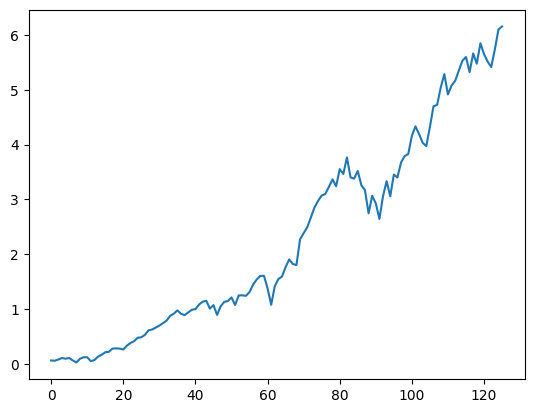

In [83]:
import matplotlib.pyplot as plt
plt.plot(cum_returns)
plt.show()